## Packages


In [49]:
#| code-summary: 'Import packages'
# Dataset packages
from datasets import load_dataset

# Data packages
import pandas as pd
pd.set_option('display.max_colwidth', None) #default: 50 chars
pd.set_option('display.max_columns', None) #default: 20 columns
import numpy as np

# NLP packages
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from bertopic import BERTopic
from gensim.models import CoherenceModel

# NLP packages
import spacy
import gensim.downloader as api
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from langdetect import detect

import nltk
from nltk.corpus import stopwords

import torch
import seaborn
import matplotlib.pyplot as plt

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import hdbscan
import umap

from sentence_transformers import SentenceTransformer #https://huggingface.co/sentence-transformers/all-mpnet-base-v2

from wordcloud import WordCloud

import gensim.corpora as corpora
import gensim

## Moving Model and Data to GPU
It is generally faster to run on your GPU if available. This code checks for availability and subsequent code will move the model and data batches to the assigned device. (taken from lab 9)

In [50]:
if torch.cuda.is_available():
    device = torch.device('cuda') # NVIDIA GPU
elif torch.backends.mps.is_available():
    device = torch.device('mps') # Apple GPU
else:
    device = torch.device('cpu') # Fallback CPU
print('Using device:', device)

Using device: mps


In [51]:
np.random.seed(42)

# Datasets
Install the datasets from Huggingface. Needs to be done using read_parquet.

In [52]:
bladee   = pd.read_parquet("hf://datasets/huggingartists/bladee@refs/convert/parquet/default/train/0000.parquet")
yunglean = pd.read_parquet("hf://datasets/huggingartists/yung-lean@refs/convert/parquet/default/train/0000.parquet")
xxx   = pd.read_parquet("hf://datasets/huggingartists/xxxtentacion@refs/convert/parquet/default/train/0000.parquet")
lilpeep   = pd.read_parquet("hf://datasets/huggingartists/lil-peep@refs/convert/parquet/default/train/0000.parquet")
bladee["artist"]   = "bladee"
yunglean["artist"] = "yung lean"
xxx["artist"]   = "xxxtentacion"
lilpeep["artist"] = "lil peep"

In [53]:
df = pd.concat([bladee, yunglean, xxx, lilpeep], ignore_index=True)[["artist", "text"]]

In [54]:
print(f"Initial Number of Bladee Songs = {len(df[df['artist']=="bladee"])}")
print(f"Initial Number of Yung Lean Songs = {len(df[df['artist']=="yung lean"])}")
print(f"Initial Number of Lil Peep Songs = {len(df[df['artist']=="lil peep"])}")
print(f"Initial Number of XXXTentacion Songs = {len(df[df['artist']=="xxxtentacion"])}")
print(len(df))

Initial Number of Bladee Songs = 318
Initial Number of Yung Lean Songs = 269
Initial Number of Lil Peep Songs = 547
Initial Number of XXXTentacion Songs = 784
1918


## Cleaning choices made

In [55]:
df = df.drop_duplicates() #some songs are included multiple times 
# Source - https://stackoverflow.com/a/70771731
# Posted by Barth
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df = df.replace("\s+", " ", regex=True).apply(lambda x: x.str.strip()) #Remove access white space
df['text'] = df['text'].str.lower()

df = df[~df["text"].str.startswith(("lyrics", "not available"), na=False)] #"lyrics from "

df = df[~df["text"].str.contains(("lyrics"), na=False)] # cleaning process after looking at database some just talking about the lyrics 

# Source - https://stackoverflow.com/a/56708633
# Posted by coldspeed95, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df = df[df['text'].str.strip().astype(bool)] #remove empty rows 

df['text'] = df['text'].str.replace(r'\b(\w+)\s+\1,*\b', r'\1', regex=True, case=False) #songs so words like "yeah yeah yeah "
df['text'] = df['text'].str.replace(r'\ba+y+', r'', regex=True, case=False) #remove adlibs
df['text'] = df['text'].str.replace(r'\bo+h+', r'', regex=True, case=False) #remove adlibs

df = df[df["text"].apply(len)>20] #dataset included tweets and other short messages 

# Source - https://stackoverflow.com/a/67789744
# Posted by Ank, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df = df[df['text'].apply(detect).eq('en')] #some songs by Bladee are in Swedish, and fan attribution to peep in Spanish and Russian 

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/var/folders/_d/jmptf6h503s9xxpwhlh2g6m00000gn/T/ipykernel_5715/2849055883.py:6: SyntaxWarning: invalid escape sequence '\s'
  df = df.replace("\s+", " ", regex=True).apply(lambda x: x.str.strip()) #Remove access white space


In [56]:
print(f"Initial Number of Bladee Songs = {len(df[df['artist']=="bladee"])}")
print(f"Initial Number of Yung Lean Songs = {len(df[df['artist']=="yung lean"])}")
print(f"Initial Number of Lil Peep Songs = {len(df[df['artist']=="lil peep"])}")
print(f"Initial Number of XXXTentacion Songs = {len(df[df['artist']=="xxxtentacion"])}")
print(len(df))
#want to delete rows to ensure 240 samples per artist 
df = pd.concat([df[df["artist"]=="bladee"].sample(n=240), df[df["artist"]=="yung lean"].sample(n=240), df[df["artist"]=="lil peep"].sample(n=240), df[df["artist"]=="xxxtentacion"].sample(n=240)])

Initial Number of Bladee Songs = 280
Initial Number of Yung Lean Songs = 243
Initial Number of Lil Peep Songs = 483
Initial Number of XXXTentacion Songs = 543
1549


In [57]:
print(len(df))

960


## Sentiment Analysis using Vader before any embeddings

In [58]:
#sentiment analyzer
sid = SentimentIntensityAnalyzer()
for row in df:
    df['sentiment_score'] = df['text'].apply(lambda song: sid.polarity_scores(song)['compound'])

### Graphing Sentiment Analysis 

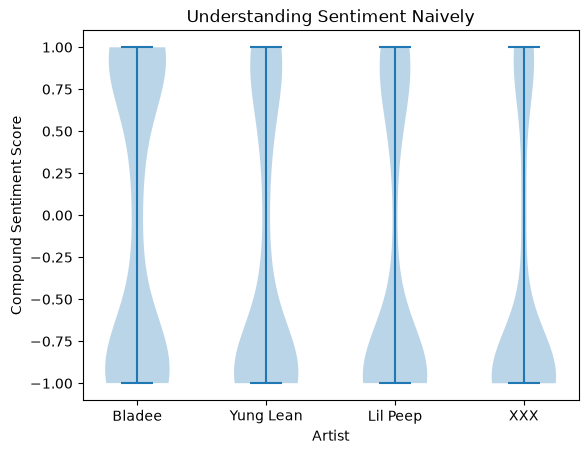

In [59]:

bladee_sentiment = df[df['artist']== 'bladee']
yunglean_sentiment = df[df['artist']== 'yung lean']
lilpeep_sentiment = df[df['artist']== 'lil peep']
xxx_sentiment = df[df['artist']== 'xxxtentacion']

data_to_chart = [bladee_sentiment["sentiment_score"], yunglean_sentiment["sentiment_score"], lilpeep_sentiment["sentiment_score"], xxx_sentiment["sentiment_score"]]
plt.violinplot(data_to_chart)

plt.xlabel('Artist')
plt.ylabel('Compound Sentiment Score')
plt.title('Understanding Sentiment Naively')
plt.xticks([1,2,3,4],["Bladee", "Yung Lean", "Lil Peep", "XXX"])
plt.show()

# BERTopic

In [163]:
nltk.download("stopwords")  #changing custom stop words, because spacy was removing too many words to understand any context 
stop_words_special = set(stopwords.words("english"))

stop_words_special.update(["yeah", "nah", "mmm", "im", "like"])

#| code-summary: 'Configure and train BERTopic with (mostly) default settings'
#| code-fold: false
docs = df['text'].tolist() # keep only 'text'


# Configure
topic_model = BERTopic(   
    embedding_model="all-mpnet-base-v2",         # (defaults)
    # 3. Clustering
    min_topic_size = 15,            # (10) important! equivalent to HDBSCAN min_cluster_size
    
    # 4. Tokenizer/Vectorizer       # (CountVectorizer())
    vectorizer_model = CountVectorizer(stop_words=list(stop_words_special), min_df=2), #use of my custom stop words from above
    
    # 5. cTF-IDF -> Topic-Terms
    top_n_words = 10,               # (10) increase for more detailed topic descriptions
    nr_topics = None,               # (None) heed warnings!
)
# Train
topics, probs = topic_model.fit_transform(docs) # topics, probs may get updated later so we later use "live" attributes instead!
print(f'Initial number of topics (incl. -1): {topic_model.get_topic_info().shape[0]}')
print(f'Initial vocabulary size: {len(topic_model.vectorizer_model.get_feature_names_out())}\n')

[nltk_data] Downloading package stopwords to /Users/aj/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4670.27it/s]


Initial number of topics (incl. -1): 8
Initial vocabulary size: 4699



In [164]:
#| code-summary: 'Display the topic summary by document count order'
#| code-fold: false
display(topic_model.get_topic_info().shape) #names by 4 most common words 
topic_model.get_topic_info().iloc[:, :-1].head(10) # MODIFY: to see more/less topics (omit Representative_Docs)

(8, 5)

,Topic,Count,Name,Representation
0,-1,375,-1_dont_fuck_got_know,"[dont, fuck, got, know, cant, get, wanna, go, see, make]"
1,0,183,0_bitch_fuck_nigga_shit,"[bitch, fuck, nigga, shit, got, huh, pussy, dont, niggas, know]"
2,1,125,1_love_girl_know_dont,"[love, girl, know, dont, one, baby, youre, time, wanna, get]"
3,2,89,2_go_let_know_feel,"[go, let, know, feel, cant, seem, pain, mind, gone, one]"
4,3,69,3_lean_got_shawty_know,"[lean, got, shawty, know, yung, get, fuck, dont, bitch, diamonds]"
5,4,48,4_thaiboy_dont_drain_cant,"[thaiboy, dont, drain, cant, lost, got, million, go, gang, one]"
6,5,35,5_ice_world_way_see,"[ice, world, way, see, take, rainbow, snow, life, road, go]"
7,6,21,6_flex_got_lean_ima,"[flex, got, lean, ima, flare, solar, boys, see, almost, big]"


In [62]:
#| code-summary: 'Analyze one topic by its raw word scores'
topic_model.get_topic(0)

[('love', np.float64(0.04565375816722348)),
 ('dont', np.float64(0.039187695158852925)),
 ('know', np.float64(0.03911964617559347)),
 ('girl', np.float64(0.038998529528087)),
 ('baby', np.float64(0.03862821118151364)),
 ('one', np.float64(0.0346653240738947)),
 ('youre', np.float64(0.032145463868994424)),
 ('time', np.float64(0.03011293915709125)),
 ('wanna', np.float64(0.026532921219217163)),
 ('cant', np.float64(0.025437306908621))]

In [63]:
#https://maartengr.github.io/BERTopic/getting_started/visualization/visualization.html#visualize-documents
topic_model.visualize_topics()

In [64]:
#Consider setting topic names 
#topic_model.set_topic_labels({0: 'Cars', 1: 'Sports', 2: 'Religion'}) # MODIFY: rename to better labels

In [65]:
topic_model.visualize_barchart()

In [66]:
#| code-summary: "Visualize topic embeddings' cosine similarities and look for clusters of topics"
topic_model.visualize_heatmap( # (defaults)
    use_ctfidf = False,        # (False) map embeddings / True: map cTF-IDF weights
    #n_clusters = 10,           # (None) <- MODIFY: powerful! creates ordered CLUSTERS of similar topics
    top_n_topics = None,       # (None) all
    custom_labels = True,      # (False)
)

In [67]:
topic_model.visualize_term_rank()

In [68]:
#| code-summary: 'Display the document summary by document number order'
topic_model.get_document_info(docs)[['Topic', 'Name', 'Top_n_words', 'Probability']].head()

,Topic,Name,Top_n_words,Probability
0,-1,-1_dont_fuck_bitch_got,dont - fuck - bitch - got - know - get - cant - make - aint - go,0.000000
1,4,4_ice_way_life_world,ice - way - life - world - rainbow - man - see - watch - take - let,0.900481
2,3,3_thaiboy_drain_dont_cant,thaiboy - drain - dont - cant - lost - gang - go - got - get - know,0.934400
3,-1,-1_dont_fuck_bitch_got,dont - fuck - bitch - got - know - get - cant - make - aint - go,0.000000
4,3,3_thaiboy_drain_dont_cant,thaiboy - drain - dont - cant - lost - gang - go - got - get - know,0.895925


### Grouping by artists 

In [70]:
#https://maartengr.github.io/BERTopic/getting_started/topicsperclass/topicsperclass.html

classes = df["artist"]
topics_per_class = topic_model.topics_per_class(docs, classes=classes)
topic_model.visualize_topics_per_class(topics_per_class, top_n_topics=10)

### Calculate the similarity by topic

In [98]:
similarity[similarity["Class"] == similarity["Class"][1]]

,Topic,Words,Frequency,Class,Name
1,0,"love, baby, uh, drama, know",26,bladee,0_love_dont_know_girl
2,1,"gone, feel, know, try, away",29,bladee,1_know_seem_feel_go
3,2,"bustin, fuck, bitch, pull, hey",2,bladee,2_bitch_fuck_nigga_shit
4,3,"thaiboy, drain, dont, cant, lost",58,bladee,3_thaiboy_drain_dont_cant
5,4,"ice, way, world, rainbow, road",18,bladee,4_ice_way_life_world
7,6,"flex, existence, vision, nice, boys",3,bladee,6_flex_force_air_got
9,10,"got, nose, black, cherry, lean",4,bladee,10_lean_back_know_man
10,12,"die, cry, wrist, til, cady",3,bladee,12_die_cry_wrist_take


In [105]:
topics_per_class
similarity

,Topic,Words,Frequency,Class,Name
1,0,"love, baby, uh, drama, know",26,bladee,0_love_dont_know_girl
2,1,"gone, feel, know, try, away",29,bladee,1_know_seem_feel_go
3,2,"bustin, fuck, bitch, pull, hey",2,bladee,2_bitch_fuck_nigga_shit
4,3,"thaiboy, drain, dont, cant, lost",58,bladee,3_thaiboy_drain_dont_cant
5,4,"ice, way, world, rainbow, road",18,bladee,4_ice_way_life_world
7,6,"flex, existence, vision, nice, boys",3,bladee,6_flex_force_air_got
9,10,"got, nose, black, cherry, lean",4,bladee,10_lean_back_know_man
10,12,"die, cry, wrist, til, cady",3,bladee,12_die_cry_wrist_take
12,0,"love, dont, girl, know, one",85,lil peep,0_love_dont_know_girl
13,1,"clearer, back, know, never, jack",2,lil peep,1_know_seem_feel_go


In [161]:
# Equation was found https://aile3.ijs.si/dunja/SiKDD2022/Papers/SiKDD2022_paper_5269.pdf
similarity = topics_per_class[topics_per_class["Topic"]!= -1 ]
similarity = similarity[similarity["Frequency"]!= 1]

classes = similarity["Class"].unique()   # don't assume 0..3

similarity_topic = {}
for i in range(len(classes)):
    c1 = classes[i]
    artist1_df = similarity[similarity["Class"] == c1]
    topics1 = set(artist1_df["Topic"])
    for j in range(len(classes)):
        c2 = classes[j]
        artist2_df = similarity[similarity["Class"] == c2]
        topics2 = set(artist2_df["Topic"])
        #intersection = len(topics1 - topics2)      # topics in 1 but not 2
        similarity_topic[f"{c1} and {c2}"] = len(topics1.intersection(topics2)) / len(topics1)

In [162]:
#https://www.geeksforgeeks.org/python/python-sort-a-dictionary/
sorted(similarity_topic.items(), key=lambda item: item[1])

[('yung lean and xxxtentacion', 0.3333333333333333),
 ('bladee and xxxtentacion', 0.5),
 ('yung lean and lil peep', 0.5833333333333334),
 ('bladee and lil peep', 0.625),
 ('lil peep and bladee', 0.625),
 ('lil peep and xxxtentacion', 0.625),
 ('yung lean and bladee', 0.6666666666666666),
 ('xxxtentacion and bladee', 0.8),
 ('xxxtentacion and yung lean', 0.8),
 ('lil peep and yung lean', 0.875),
 ('bladee and bladee', 1.0),
 ('bladee and yung lean', 1.0),
 ('lil peep and lil peep', 1.0),
 ('xxxtentacion and lil peep', 1.0),
 ('xxxtentacion and xxxtentacion', 1.0),
 ('yung lean and yung lean', 1.0)]

## Tokenizing 

In [71]:
#from lab 2 
nlp = spacy.load('en_core_web_sm')

nltk.download("stopwords")  #changing custom stop words, because spacy was removing too many words to understand any context 
stop_words = set(stopwords.words("english"))

stop_words.update(["yeah", "nah", "mmm"])

#| code-summary: "spaCy tokenize on dataset"
#| code-fold: false
docs_as_tokens = list(nlp.pipe(df['text'])) # entire dataset
df['tokens_spacy'] = [
    [token.text for token in doc if not token.is_punct if token.text not in stop_words] # no normalization
    for doc in docs_as_tokens] # per-document
df[['text', 'tokens_spacy']].sample(2)

#More cleaning of tokens 
df["tokens_spacy"] = df["tokens_spacy"].apply(
    lambda items: [s for s in items if len(s) >= 3] #removing short tokens that aren't words
)

df = df[df["tokens_spacy"].apply(len)>20] #dataset included tweets and other short messages 

#verification of the findings through examining a csv file for manual changes 
# Source - https://stackoverflow.com/a/66104513
# Posted by LePuppy, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df.to_csv('cleaned_file.csv', index = False)


[nltk_data] Downloading package stopwords to /Users/aj/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# LDA Topic Modelling

In [72]:
def lemmatize(tokens):
    doc = nlp(" ".join(tokens))
    return [token.lemma_ for token in doc]

df['lemmas'] = df['tokens_spacy'].apply(lemmatize)

In [73]:
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts = df['lemmas']
corpus = [id2word.doc2bow(text) for text in texts]

In [122]:
lda_model = gensim.models.ldamodel.LdaModel(corpus=corpus,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

In [123]:
# Print the topics
topics = lda_model.print_topics(num_words=8)
for topic in topics:
    print(topic)

(0, '0.131*"cry" + 0.065*"way" + 0.062*"wait" + 0.050*"promise" + 0.044*"swear" + 0.042*"let" + 0.039*"time" + 0.037*"dark"')
(1, '0.129*"walk" + 0.077*"pistol" + 0.045*"yes" + 0.032*"october" + 0.024*"lonely" + 0.021*"nowhere" + 0.021*"grip" + 0.020*"less"')
(2, '0.078*"single" + 0.032*"crash" + 0.032*"bread" + 0.021*"going" + 0.016*"sunrise" + 0.014*"sucker" + 0.012*"golden" + 0.011*"fiji"')
(3, '0.130*"fuck" + 0.061*"bitch" + 0.047*"shit" + 0.030*"like" + 0.028*"dick" + 0.021*"yuh" + 0.021*"man" + 0.018*"give"')
(4, '0.104*"huh" + 0.040*"hey" + 0.038*"bad" + 0.036*"let" + 0.035*"fall" + 0.034*"around" + 0.032*"want" + 0.021*"feel"')
(5, '0.151*"dance" + 0.010*"ache" + 0.007*"cady" + 0.003*"imaginary" + 0.003*"ancient" + 0.002*"void" + 0.001*"cadycutthroat" + 0.000*"pant"')
(6, '0.188*"like" + 0.040*"nigga" + 0.035*"talk" + 0.029*"put" + 0.024*"damn" + 0.023*"bitch" + 0.021*"god" + 0.019*"shawty"')
(7, '0.049*"december" + 0.047*"2016" + 0.043*"2015" + 0.038*"may" + 0.035*"march" + 0.

### Coherency Scores 

In [135]:
# Compute coherence score
coherency_dict = {}
coherence_model_lda = CoherenceModel(model=lda_model, texts=df['lemmas'], dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()

coherency_dict["Overall Coherency"] = round(coherence_lda, 3) 

print('\nCoherence Score: ', coherence_lda)


Coherence Score:  0.366081063185261


### Diversity Scores

In [143]:
#| code-summary: 'Define evaluation functions to measure coherence and diversity'
#Taken from lab, augmented for dictionary 
dict_diversity = {}
def get_diversity_octis(topics, name, topn=10, d = dict_diversity ):
    '''Calculate topic diversity. Code ref: https://github.com/MIND-Lab/OCTIS.'''
    unique_words = set()
    for topic in topics:
        unique_words = unique_words.union(set(topic[:topn]))
    score = len(unique_words) / (topn * len(topics))
    d[name] = round(score, 3)
    return 

### Uniqueness 

In [136]:
#| code-summary: 'Define evaluation functions to measure coherence and diversity'
#Taken from lab, augmented for dictionary 
uniqueness_dict = {}
def uniqueness(topics, name, dict=uniqueness_dict):
    unique_words = set()
    len_topic = 0
    for topic in topics:
        len_topic += len(topic)
        unique_words = unique_words.union(set(topic))
    unique_score = len(unique_words) / (len_topic)
    dict[name] = {"uniqueness: ": round(unique_score,3), "number of unique words: ": len(unique_words), "number of all words: ": len_topic}
    return 

### Examining the artists individually for topics, coherency, and diversity 

#### Bladee

(0, '0.139*"way" + 0.056*"around" + 0.028*"swear" + 0.016*"area" + 0.009*"fun" + 0.007*"mirror" + 0.007*"light" + 0.006*"fly" + 0.005*"tunnel" + 0.004*"d-925"')
(1, '0.072*"side" + 0.023*"friday" + 0.018*"far" + 0.015*"goin" + 0.015*"life" + 0.014*"to" + 0.014*"afterlife" + 0.012*"follow" + 0.012*"rest" + 0.011*"crawl"')
(2, '0.047*"snowman" + 0.005*"frosty" + 0.004*"shoulder" + 0.004*"pink" + 0.003*"shape" + 0.002*"exile" + 0.002*"rave" + 0.002*"pencil" + 0.002*"signal" + 0.002*"cancel"')
(3, '0.024*"fuck" + 0.020*"magic" + 0.017*"boy" + 0.016*"family" + 0.013*"get" + 0.013*"give" + 0.011*"crush" + 0.010*"gang" + 0.009*"man" + 0.009*"understand"')
(4, '0.040*"play" + 0.040*"love" + 0.032*"lose" + 0.032*"get" + 0.023*"victim" + 0.020*"want" + 0.017*"strike" + 0.013*"pray" + 0.013*"grip" + 0.012*"ocean"')
(5, '0.029*"mind" + 0.023*"ache" + 0.022*"die" + 0.020*"til" + 0.014*"cady" + 0.013*"call" + 0.012*"imma" + 0.007*"imaginary" + 0.006*"dirty" + 0.003*"ancient"')
(6, '0.048*"drama" + 0

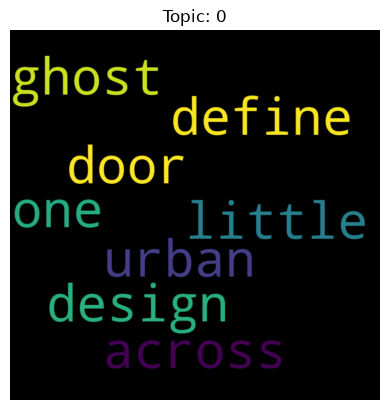

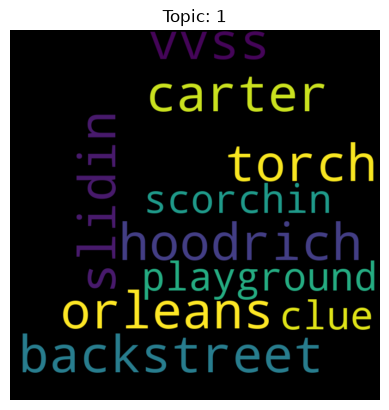

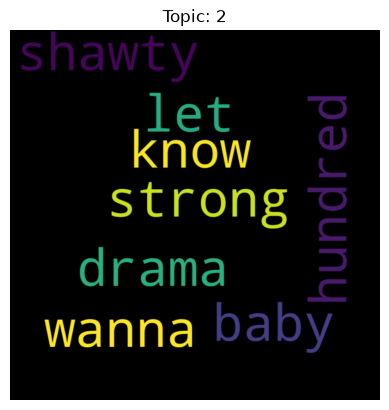

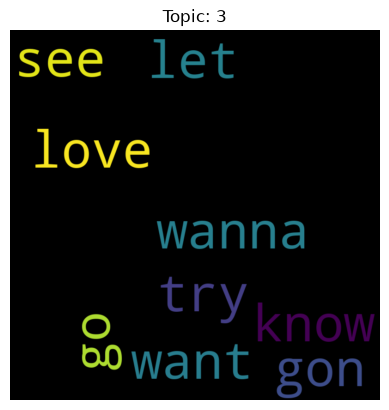

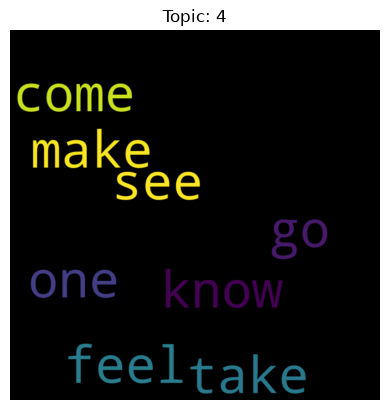


Coherence Score Bladee:  0.38831866220665867


In [144]:
# bladee
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_b = df.loc[df["artist"] == "bladee", "lemmas"].tolist()
corpus_b = [id2word.doc2bow(text) for text in texts_b]
lda_model_b = gensim.models.ldamodel.LdaModel(corpus=corpus_b,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_b = lda_model_b.print_topics(num_words=10)
for topic in topics_b:
    print(topic)

get_diversity_octis(df.loc[df["artist"] == "bladee", "tokens_spacy"].tolist(), "bladee")
uniqueness(df.loc[df["artist"] == "bladee", "tokens_spacy"].tolist(), "bladee")

for topic_id, topic in enumerate(lda_model_b.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_b, texts=texts_b, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["Bladee Coherency"] = round(coherence_lda, 3)
print('\nCoherence Score Bladee: ', coherence_lda)

#### Yung Lean

(0, '0.036*"flame" + 0.032*"away" + 0.018*"10k" + 0.017*"blowin" + 0.012*"stay" + 0.011*"name" + 0.011*"rollin" + 0.010*"ten" + 0.010*"nowhere" + 0.009*"tangerine"')
(1, '0.041*"see" + 0.018*"kush" + 0.015*"open" + 0.014*"mind" + 0.013*"angel" + 0.011*"keep" + 0.011*"fuck" + 0.010*"say" + 0.009*"inside" + 0.009*"die"')
(2, '0.040*"crystal" + 0.008*"sheet" + 0.005*"blind" + 0.005*"section" + 0.005*"pearl" + 0.003*"pokémon" + 0.002*"else" + 0.002*"toyota" + 0.002*"expire" + 0.002*"steezin"')
(3, '0.038*"like" + 0.030*"shawty" + 0.022*"two" + 0.016*"pay" + 0.015*"sippin" + 0.014*"get" + 0.014*"night" + 0.013*"day" + 0.013*"whip" + 0.013*"pill"')
(4, '0.026*"walk" + 0.023*"honda" + 0.021*"trust" + 0.018*"leave" + 0.015*"tint" + 0.013*"paralyzed" + 0.012*"weather" + 0.010*"want" + 0.010*"night" + 0.010*"wind"')
(5, '0.025*"suicide" + 0.005*"inna" + 0.004*"vader" + 0.004*"darth" + 0.003*"doer" + 0.003*"ziploc" + 0.003*"obi" + 0.002*"wan" + 0.002*"fable" + 0.002*"blazer"')
(6, '0.030*"know" +

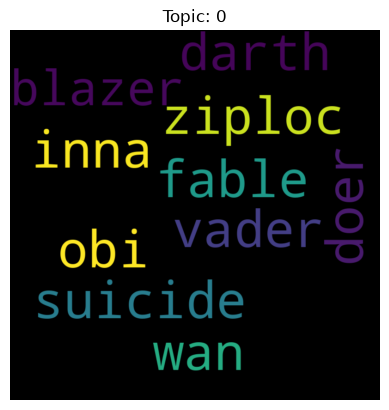

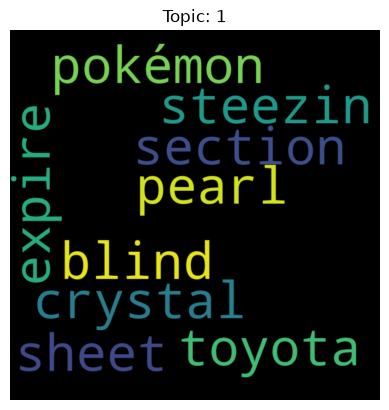

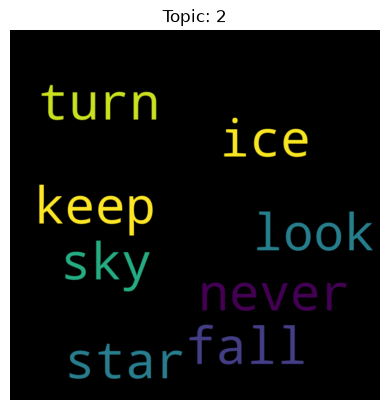

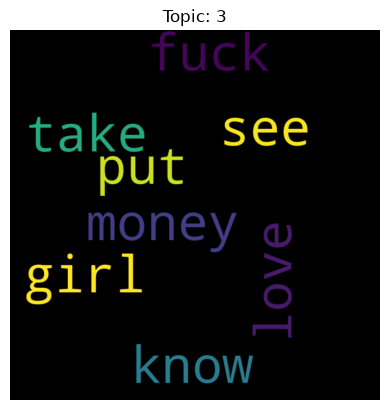

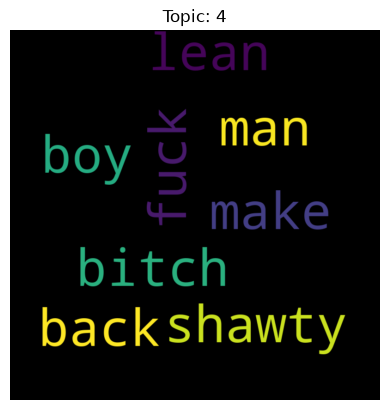


Coherence Score Yung Lean:  0.3840070725158115


In [145]:
#yung lean
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_yl = df.loc[df["artist"] == "yung lean", "lemmas"].tolist()
corpus_yl = [id2word.doc2bow(text) for text in texts_yl]
lda_model_yl = gensim.models.ldamodel.LdaModel(corpus=corpus_yl,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_yl = lda_model_yl.print_topics(num_words=10)
for topic in topics_yl:
    print(topic)

get_diversity_octis(df.loc[df["artist"] == "yung lean", "tokens_spacy"].tolist(), "yung lean")
uniqueness(df.loc[df["artist"] == "yung lean", "tokens_spacy"].tolist(), "yung lean")

for topic_id, topic in enumerate(lda_model_yl.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_yl, texts=texts_yl, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["Yung Lean Coherency"] = round(coherence_lda, 3)
print('\nCoherence Score Yung Lean: ', coherence_lda)

#### Lil Peep

(0, '0.057*"deathwish" + 0.028*"boy" + 0.025*"want" + 0.016*"think" + 0.015*"twist" + 0.009*"give" + 0.008*"clap" + 0.008*"see" + 0.007*"crack" + 0.007*"his-"')
(1, '0.034*"cocaine" + 0.031*"nowhere" + 0.030*"anyone" + 0.026*"find" + 0.021*"go" + 0.016*"shawty" + 0.015*"latitude" + 0.015*"attitude" + 0.015*"avenue" + 0.014*"mad"')
(2, '0.057*"fall" + 0.043*"rain" + 0.038*"watch" + 0.037*"let" + 0.032*"keep" + 0.027*"promise" + 0.025*"come" + 0.022*"tear" + 0.022*"like" + 0.020*"around"')
(3, '0.058*"dis" + 0.040*"bih" + 0.034*"2016" + 0.031*"cruise" + 0.027*"2015" + 0.019*"2017" + 0.017*"panic" + 0.017*"november" + 0.015*"awful" + 0.014*"song"')
(4, '0.039*"stop" + 0.036*"fuck" + 0.028*"get" + 0.024*"past" + 0.018*"heart" + 0.018*"rent" + 0.017*"pay" + 0.016*"till" + 0.014*"give" + 0.014*"woah"')
(5, '0.016*"turnin" + 0.007*"somebody" + 0.007*"stock" + 0.005*"small" + 0.003*"selfish" + 0.003*"pointless" + 0.003*"town" + 0.002*"gram" + 0.001*"truth" + 0.001*"stockfish"')
(6, '0.038*"kno

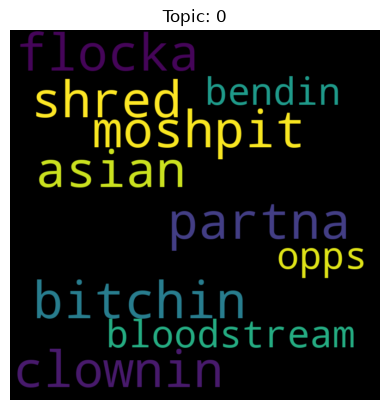

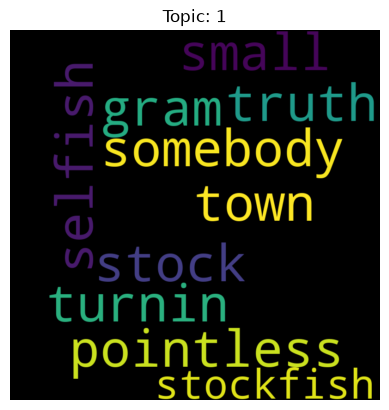

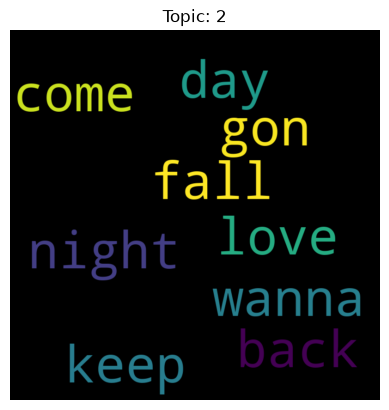

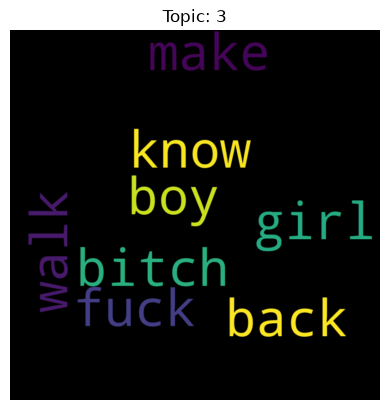

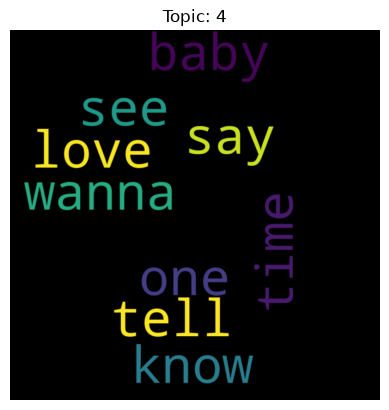


Coherence Score Lil peep:  0.3848399963002212


In [146]:
# lil peep
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_lp = df.loc[df["artist"] == "lil peep", "lemmas"].tolist()
corpus_lp = [id2word.doc2bow(text) for text in texts_lp]
lda_model_lp = gensim.models.ldamodel.LdaModel(corpus=corpus_lp,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_lp = lda_model_lp.print_topics(num_words=10)
for topic in topics_lp:
    print(topic)

get_diversity_octis(df.loc[df["artist"] == "lil peep", "tokens_spacy"].tolist(), "lil peep")
uniqueness(df.loc[df["artist"] == "lil peep", "tokens_spacy"].tolist(), "lil peep")

for topic_id, topic in enumerate(lda_model_lp.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_lp, texts=texts_lp, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["Lil Peep Coherency"] = round(coherence_lda, 3)
print('\nCoherence Score Lil peep: ', coherence_lda)

#### XXXTentacion

(0, '0.000*"run" + 0.000*"know" + 0.000*"pistol" + 0.000*"get" + 0.000*"head" + 0.000*"bitch" + 0.000*"lose" + 0.000*"feel" + 0.000*"cry" + 0.000*"end"')
(1, '0.057*"test" + 0.011*"dem" + 0.007*"gyal" + 0.007*"yuh" + 0.007*"come" + 0.006*"bop" + 0.006*"big" + 0.005*"kodak" + 0.005*"inna" + 0.004*"burnin"')
(2, '0.045*"obvious" + 0.032*"molly" + 0.031*"slatt" + 0.028*"stand" + 0.022*"fall" + 0.017*"okay" + 0.014*"change" + 0.013*"put" + 0.013*"rain" + 0.012*"realize"')
(3, '0.088*"like" + 0.034*"nigga" + 0.031*"get" + 0.024*"bitch" + 0.020*"talk" + 0.020*"say" + 0.015*"even" + 0.014*"please" + 0.014*"gon" + 0.011*"maybe"')
(4, '0.033*"want" + 0.029*"wait" + 0.023*"love" + 0.022*"smoke" + 0.020*"cause" + 0.019*"shine" + 0.017*"keep" + 0.014*"say" + 0.012*"hate" + 0.012*"need"')
(5, '0.157*"ahead" + 0.065*"dick" + 0.065*"suck" + 0.037*"shawty" + 0.015*"sandas" + 0.008*"whippin" + 0.006*"yuh" + 0.002*"vool" + 0.002*"shotty" + 0.002*"illuminati"')
(6, '0.060*"know" + 0.023*"n’t" + 0.018*"le

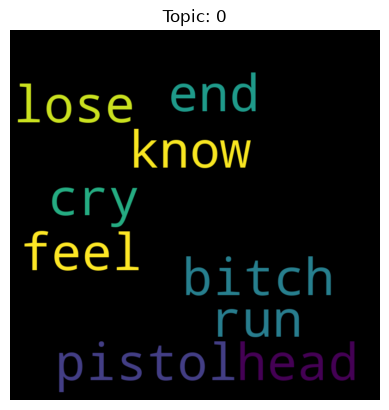

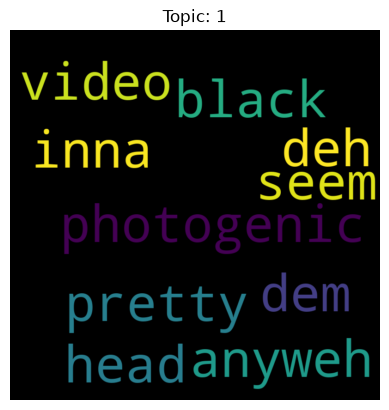

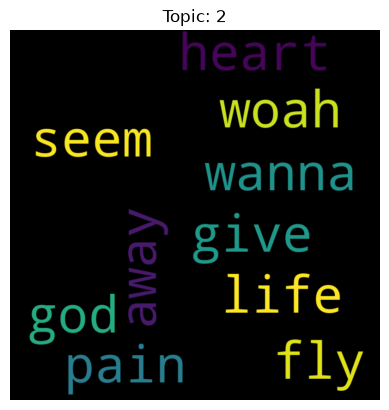

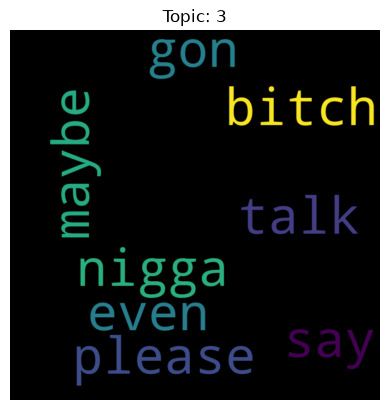

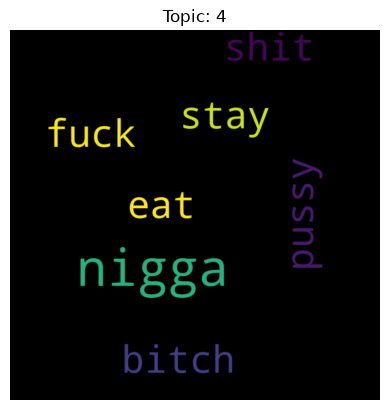


Coherence Score XXXTentacion:  0.3753552713754536


In [147]:
#xxx
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_xxx = df.loc[df["artist"] == "xxxtentacion", "lemmas"].tolist()
corpus_xxx = [id2word.doc2bow(text) for text in texts_xxx]
lda_model_xxx = gensim.models.ldamodel.LdaModel(corpus=corpus_xxx,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_xxx = lda_model_xxx.print_topics(num_words=10)
for topic in topics_xxx:
    print(topic)
    
get_diversity_octis(df.loc[df["artist"] == "xxxtentacion", "tokens_spacy"].tolist(), "xxxtentacion")
uniqueness(df.loc[df["artist"] == "xxxtentacion", "tokens_spacy"].tolist(), "xxxtentacion")

for topic_id, topic in enumerate(lda_model_xxx.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_xxx, texts=texts_xxx, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["XXXTentacion Coherency"] = round(coherence_lda, 3)
print('\nCoherence Score XXXTentacion: ', coherence_lda)

# Coherency and Uniqueness Scores 

In [148]:
print(f'Coherency Scores : {coherency_dict}')
print(f"Uniqueness Scores: {uniqueness_dict}")
print(f'Diversity Scores : {dict_diversity}')

Coherency Scores : {'Overall Coherency': np.float64(0.366), 'Bladee Coherency': np.float64(0.388), 'Yung Lean Coherency': np.float64(0.384), 'Lil Peep Coherency': np.float64(0.385), 'XXXTentacion Coherency': np.float64(0.375)}
Uniqueness Scores: {'bladee': {'uniqueness: ': 0.131, 'number of unique words: ': 4256, 'number of all words: ': 32552}, 'yung lean': {'uniqueness: ': 0.136, 'number of unique words: ': 5515, 'number of all words: ': 40672}, 'lil peep': {'uniqueness: ': 0.107, 'number of unique words: ': 3749, 'number of all words: ': 34907}, 'xxxtentacion': {'uniqueness: ': 0.145, 'number of unique words: ': 5332, 'number of all words: ': 36683}}
Diversity Scores : {'bladee': 0.419, 'yung lean': 0.445, 'lil peep': 0.37, 'xxxtentacion': 0.39}


# Topic Modelling Evaluation Metrics

The evaluation of the quality of the resulting topics from topic modelling is inherently subjective and requires **human oversight**. There are however several commonly used metrics that can be part of your evaluation strategy together with human interpretation. A good overview is provided by [Abdelrazek et al. (2023)](https://www.sciencedirect.com/science/article/abs/pii/S0306437922001090). We look at **coherence** and **diversity** here, which were used in the BERTopic [paper](https://arxiv.org/abs/2203.05794) to compare performance against other topic modelling approaches and variations of embedding models within its own flexible framework.

**Coherence** aims to measure semantic **similarity WITHIN** each topic by calculating how often the top N terms in a topic (as word pairs) co-occur in the corpus. See papers by [Newman et al. (2010)](https://aclanthology.org/N10-1012.pdf) and [Syed & Spruit (2017)](https://ieeexplore.ieee.org/abstract/document/8259775).
- Coherence requires each topic's **top N words** and the **corpus** to check for co-occurrence of word pairs along a sliding window of variable size.
- We use **Gensim's** [CoherenceModel](https://radimrehurek.com/gensim/models/coherencemodel.html) implementation.
- There are several measures of coherence. Here, we use Normalized Pointwise Mutual Information (NPMI) by default which varies in the range of [-1, 1]

**Diversity** aims to measure each topic's **uniqueness COMPARED TO** other topics by calculating the percentage of unique words in the top N words of each topic, and is briefly desribed by [Dieng et al. (2020)](https://direct.mit.edu/tacl/article/doi/10.1162/tacl_a_00325/96463/Topic-Modeling-in-Embedding-Spaces).
- Diversity only requires each topic's **top N words** and varies from [0, 1]
- We define a simple function to calculate diversity directly copying code from the [TopicDiversity](https://github.com/MIND-Lab/OCTIS/blob/master/octis/evaluation_metrics/diversity_metrics.py) class of the **[OCTIS](https://github.com/MIND-Lab/OCTIS)** package.

In [152]:
#taken from lab
#| code-summary: 'Define evaluation functions to measure coherence and diversity'
def get_diversity_octis(topics, topn=10):
    '''Calculate topic diversity. Code ref: https://github.com/MIND-Lab/OCTIS.'''
    unique_words = set()
    for topic in topics:
        unique_words = unique_words.union(set(topic[:topn]))
    return len(unique_words) / (topn * len(topics))

def evaluate_bertopic(model_string, bertopic_model, analyzer, docs, window_size=None, topn=None, coherence_measure='c_npmi'):
    '''Calculate coherence and diversity for a BERTopic model.'''

    # Get BERTopic topics-terms (topn)
    if topn is None:
        topn = len(topic_model.get_topic(0))
    topics_topterms = [
        [word for word, score in bertopic_model.get_topic(topic_id)[:topn]]
         for topic_id in bertopic_model.get_topics()
         if topic_id != -1
    ]

    # Coherence needs docs tokenized in original order
    texts_as_tokens = [analyzer(doc) for doc in docs]
    dictionary = corpora.Dictionary(texts_as_tokens)

    tc = CoherenceModel(
        topics=topics_topterms,
        texts=texts_as_tokens, dictionary=dictionary,
        window_size=window_size, topn=topn, coherence=coherence_measure
    ).get_coherence()
    
    td = get_diversity_octis(topics_topterms, topn)

    return {'model': model_string, 'k_topics': len(topics_topterms), 'coherence': tc, 'diversity': td}

def evaluate_ldia(model_string, df_ldia_topics_terms, analyzer, docs, window_size=None, topn=None, coherence_measure='c_npmi'):
    '''Calculate coherence and diversity for a Latent Dirichelet Allocation model.'''

    # Get LDiA topics-terms (topn)
    if topn is None:
        topn = len(df_ldia_topics_topterms)
    topics_topterms = []
    topics_i = df_ldia_topics_topterms.columns.get_level_values(0).unique()
    for topic_i in topics_i:
        topics_topterms.append(df_ldia_topics_topterms[topic_i]['term'].tolist())

    # Coherence needs docs tokenized in original order
    texts_as_tokens = [analyzer(doc) for doc in docs]
    dictionary = corpora.Dictionary(texts_as_tokens)
    
    tc = CoherenceModel(
        topics=topics_topterms,
        texts=texts_as_tokens, dictionary=dictionary,
        window_size=window_size, topn=topn, coherence=coherence_measure
    ).get_coherence()
    
    td = get_diversity_octis(topics_topterms, topn)

    return {'model': model_string, 'k_topics': len(topics_topterms), 'coherence': tc, 'diversity': td}

In [153]:
#taken from lab
#| code-summary: 'Define function: create DataFrame of top constituent term/topic columns for each topic/document row'
def create_df_rows_topcols(row_col_matrix, rows_i, cols_i, col_type, topcol_n):
    '''Finds the top scoring terms (columns) from a Topic-Term matrix, and wraps into a DataFrame.'''
    list_df_rows = []
    for idx, row in enumerate(row_col_matrix):
        row_scores = [{col_type: cols_i[i], 'score': row[i]} for i in row.argsort()[:-topcol_n - 1:-1]]
        df_row = pd.DataFrame(row_scores)
        df_row.columns = pd.MultiIndex.from_product([[rows_i[idx]], df_row.columns])
        list_df_rows.append(df_row)

    return pd.concat(list_df_rows, axis=1)

## Compare with an LDiA Topic Model

In [154]:
#| code-summary: 'Run the LDiA flow, condensed from Lab 6'
k_topics_ldia = 14 # MODIFY: vs. BERTopic K topics, equalize or optimize each?

# Topic modelling
X_bow = topic_model.vectorizer_model.transform(docs)
ldia_model = LatentDirichletAllocation(n_components=k_topics_ldia)
ldia_model.fit_transform(X_bow)

# Data wrangling to view top terms per topic
ldia_topics = ldia_model.components_
ldia_topics_norm = ldia_topics / ldia_topics.sum(axis=1)[:, None]
ldia_topics_i = [f'topic_{i}' for i in range(ldia_model.n_components)]
ldia_terms = topic_model.vectorizer_model.get_feature_names_out()
df_ldia_topics_topterms = create_df_rows_topcols(ldia_topics_norm, rows_i=ldia_topics_i, cols_i=ldia_terms, col_type='term', topcol_n=10)
df_ldia_topics_topterms

topic_0           topic_1           topic_2           topic_3            \
     term     score    term     score    term     score    term     score   
0    love  0.044973    dont  0.056747    know  0.041235    time  0.024175   
1     one  0.025147    fuck  0.027810    dont  0.020897    make  0.019544   
2      uh  0.022207     get  0.021992     one  0.020424    dont  0.016589   
3     got  0.017479    give  0.021276    walk  0.012959     man  0.015782   
4    want  0.014916     got  0.020270   bitch  0.011434   wanna  0.015054   
5    dont  0.014566  shawty  0.013664     let  0.010205     got  0.013244   
6    wont  0.011893   wanna  0.012116   thats  0.009865    know  0.009687   
7    know  0.010313    know  0.010200    time  0.009273    back  0.009393   
8    make  0.009791    want  0.009821    fuck  0.009154    shit  0.008862   
9   never  0.009246  please  0.009439    keep  0.008621     pay  0.008635   

  topic_4            topic_5           topic_6           topic_7            \
     term     score     term     score    term     score    term     score   
0    cant  0.027779     dont  0.019699   bitch  0.055590   bitch  0.030434   
1    dont  0.027137     lost  0.016089   nigga  0.019822    fuck  0.029677   
2    know  0.013913     feel  0.012820    shit  0.018996    back  0.019814   
3      go  0.013809  falling  0.012469   pussy  0.016198     yuh  0.019370   
4     let  0.012351      say  0.012371    know  0.015562     get  0.016432   
5    want  0.011615     pain  0.012041  niggas  0.015436     got  0.015266   
6    make  0.011369     come  0.011868     got  0.015012    okay  0.015193   
7    feel  0.010745     rain  0.011046    fuck  0.014030  fucked  0.012699   
8     see  0.009005     love  0.011015    dick  0.012611    know  0.011364   
9   wanna  0.008881    wanna  0.010819    dont  0.012495     ima  0.010971   

     topic_8           topic_9            topic_10           topic_11  \
        term     score    term     score      term     score     term   
0       dont  0.023659    girl  0.027033     wanna  0.018673     fuck   
1       know  0.021882    head  0.025269        ha  0.015819      get   
2       aint  0.019604    fuck  0.024584  december  0.012574    bitch   
3       fuck  0.013197      go  0.017931       lie  0.011793      got   
4        man  0.012952     god  0.015190      take  0.011199     know   
5        ice  0.011944    cant  0.014412      dont  0.010990     shit   
6  everybody  0.010584     get  0.014410       die  0.010963     lean   
7      cause  0.009953      yo  0.013494      look  0.010951   fuckin   
8      girls  0.009210    make  0.008141       got  0.010079     2016   
9      money  0.009163    damn  0.008000     march  0.009466     take   

            topic_12           topic_13            
      score     term     score     term     score  
0  0.030401      got  0.016159      huh  0.029664  
1  0.012147     dont  0.011902      got  0.022662  
2  0.010772      see  0.011181    bitch  0.021345  
3  0.010471      new  0.008942     aint  0.016729  
4  0.010241    wrist  0.008137      get  0.014708  
5  0.009836      ice  0.007773    nigga  0.011417  
6  0.009496      ill  0.007705      ima  0.011205  
7  0.009071     cant  0.007640      let  0.009876  
8  0.009022      get  0.007479      hey  0.009041  
9  0.008426     know  0.007406      gon  0.008617

## Evaluate: Compare Metrics

In [155]:
#| code-summary: 'Evaluate and compare models'
#| code-fold: false
analyzer = topic_model.vectorizer_model.build_analyzer() # Equalize preprocessing
results = list()
results.append(evaluate_bertopic('BERTopic', topic_model, analyzer, docs))
results.append(evaluate_ldia('LDiA', df_ldia_topics_topterms, analyzer, docs))
pd.DataFrame(results).set_index('model').round(4)

,k_topics,coherence,diversity
model,,,
BERTopic,13,-0.0075,0.7154
LDiA,14,-0.0110,0.5071
